In [1]:
pip -q install langgraph langchain langchain-core langchain-groq groq

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import getpass

if not os.environ.get("GROQ_API_KEY"):
    os.environ["GROQ_API_KEY"] = getpass.getpass("Digite sua GROQ_API_KEY: ")
print("✅ GROQ_API_KEY configurada!")

✅ GROQ_API_KEY configurada!


In [2]:
#2) Imports
#Groq SDK: streaming token a token.
#ChatGroq (LangChain): integração com LangGraph.
#LangGraph: grafos + checkpoints + interrupções.
#Também usamos:

#MemorySaver para checkpoints (necessário para breakpoints, interrupções e time travel);
#interrupt e Command para pausar e retomar.

from typing import TypedDict, Literal

from groq import Groq

from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage

from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

In [3]:
def make_llm(temperature: float = 0.7) -> ChatGroq:
    return ChatGroq(
        model="openai/gpt-oss-120b",
        temperature=temperature,
    )

llm = make_llm()
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000023C1759C410>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000023C1964FC50>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [4]:
client = Groq()
completion = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[
        {"role": "system", "content": "Responda em PT-BR, com clareza e didática"},
        {"role": "user", "content": "Explique o que é streaming em LLM e suas utilidades"},
        

            
    ],
    temperature=0.9,
    max_completion_tokens=400,
    top_p=1,
    reasoning_effort="medium",
    stream=True,
)
for chunk in completion:
     print(chunk.choices[0].delta.content or "", end="", flush=True)
print()

**Streaming em LLM – o que é e por que é útil?**  

---

## 1. O que significa “streaming” quando falamos de LLMs?

- **Definição simples**: *Streaming* (ou *transmissão*) é a capacidade de receber a resposta de um modelo de linguagem **token por token**, à medida que ele vai gerando o texto, em vez de esperar que todo o conteúdo seja concluído antes de enviá‑lo ao usuário.

- **Token**: a menor unidade que o modelo manipula (pode ser uma palavra, parte de palavra ou símbolo). Quando o LLM gera a sequência “Olá, mundo!”, ele faz isso emitindo um token de cada vez: “Olá”, “,”, “ mundo”, “!”…

- **Modo tradicional (não‑streaming)**: o cliente envia a solicitação, o modelo processa tudo, devolve **uma única resposta completa**. O cliente só vê o resultado quando o processamento termina.

- **Modo streaming**: o cliente começa a receber os tokens assim que o modelo os produz, permitindo que a interface vá exibindo o texto em **tempo real**.

---

## 2. Como o streaming funciona na prática?

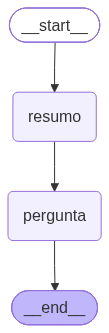

In [22]:
class StudyState(TypedDict, total=False):
    topic: str
    resumo: str
    pergunta: str

def node_resumo(state: StudyState) -> StudyState:
    topic = state.get("topic", "assunto não informado")
    resp = llm.invoke([
        SystemMessage(content="Você cria conteúdo didático em PT-BR."),
        HumanMessage(content=f"Faça um resumo bem curto (6-8 linhas) sobre: {topic}.")
    ])
    return {"resumo": resp.content}

def node_pergunta(state: StudyState) -> StudyState:
    resp = llm.invoke([
        SystemMessage(content="Você cria conteúdo didático em PT-BR."),
        HumanMessage(content=(
            "Crie 1 pergunta conceitual (com resposta curta) baseada no resumo abaixo:\n\n"
            f"{state.get('resumo','')}"
        ))
    ])
    return {"pergunta": resp.content}

builder = StateGraph(StudyState)
builder.add_node("resumo", node_resumo)
builder.add_node("pergunta", node_pergunta)
builder.add_edge(START, "resumo")
builder.add_edge("resumo", "pergunta")
builder.add_edge("pergunta", END)

study_graph = builder.compile()
study_graph


In [23]:
inputs = {"topic": "Breakpoints e depuração no LangGraph"}

for event in study_graph.stream(inputs, stream_mode="updates", ):
    print(event)

APIConnectionError: Connection error.

In [ ]:
for event in study_graph.stream(inputs, stream_mode="values"):
    print(event)

{'topic': 'Breakpoints e depuração no LangGraph'}
{'topic': 'Breakpoints e depuração no LangGraph', 'resumo': "**Breakpoints e depuração no LangGraph**\n\n- *Breakpoints* são marcadores que podem ser inseridos em nós ou transições do grafo para interromper a execução e inspecionar o estado interno.  \n- Ao atingir um breakpoint, o motor do LangGraph pausa, permitindo visualizar variáveis, contexto de mensagem e saída parcial de cada nó.  \n- A interface de depuração oferece **step‑over**, **step‑into** e **continue**, facilitando a navegação entre nós sequenciais ou ramificações.  \n- É possível definir breakpoints condicionais (ex.: “pausar só se `user_intent == 'cancel'`”).  \n- Durante a pausa, o usuário pode editar o contexto ou o payload e retomar a execução, testando correções em tempo real.  \n- Logs detalhados e visualização gráfica do fluxo ajudam a identificar gargalos ou lógica incorreta, tornando a depuração mais intuitiva."}
{'topic': 'Breakpoints e depuração no LangGraph'

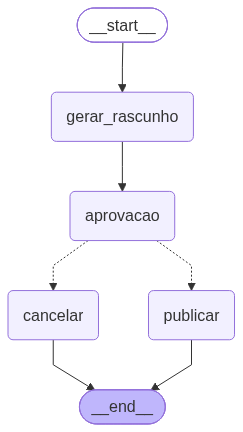

In [24]:
class PublishState(TypedDict, total=False):
    tema: str
    rascunho: str
    aprovado: bool
    publicado: str

def node_gerar_rascunho(state: PublishState) -> PublishState:
    tema = state.get("tema", "tema não informado")
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, tom neutro e didático."),
        HumanMessage(content=(
            f"Crie um rascunho curto (máx 12 linhas) de uma prática usada em sobre: {tema}.\n"
            "Inclua: definição, exemplo e um alerta de erro comum."
        ))
    ])
    return {"rascunho": resp.content}

def node_aprovacao(state: PublishState) -> Command[Literal["publicar", "cancelar"]]:
    payload = {
        "pergunta": "Você aprova o rascunho para publicação?",
        "rascunho": state.get("rascunho", "")
    }
    decisao = interrupt(payload)  # PAUSA AQUI

    if decisao is True:
        return Command(goto="publicar", update={"aprovado": True})
    return Command(goto="cancelar", update={"aprovado": False})

def node_publicar(state: PublishState) -> PublishState:
    texto = state.get("rascunho", "")
    return {"publicado": "✅ PUBLICADO (simulação)\n\n" + texto}

def node_cancelar(state: PublishState) -> PublishState:
    return {"publicado": "❌ Cancelado: o rascunho não foi aprovado."}

pub_builder = StateGraph(PublishState)
pub_builder.add_node("gerar_rascunho", node_gerar_rascunho)
pub_builder.add_node("aprovacao", node_aprovacao)
pub_builder.add_node("publicar", node_publicar)
pub_builder.add_node("cancelar", node_cancelar)

pub_builder.add_edge(START, "gerar_rascunho")
pub_builder.add_edge("gerar_rascunho", "aprovacao")
pub_builder.add_edge("publicar", END)
pub_builder.add_edge("cancelar", END)

pub_checkpointer = MemorySaver()
pub_graph = pub_builder.compile(checkpointer=pub_checkpointer)
pub_graph

In [25]:
config = {"configurable": {"thread_id": "pub-01"}}

result = pub_graph.invoke({"tema": "Príncipios básicos da computação quântica"}, config=config)
print("Interrupção recebida:")
print(result.get("__interrupt__"))

APIConnectionError: Connection error.

In [27]:
#APROVACAO HUMANA
final = pub_graph.invoke(Command(resume=True), config=config)
print(final["publicado"])

✅ PUBLICADO (simulação)

**Prática: Simulação de um qubit usando o IBM Quantum Experience**

1. **Definição** – Um *qubit* é a unidade básica de informação na computação quântica; ao contrário do bit clássico (0 ou 1), ele pode estar em uma superposição α|0⟩ + β|1⟩, onde |α|² e |β|² são as probabilidades de medição.  
2. **Objetivo** – Criar, visualizar e medir um estado de superposição simples (|+⟩ = (|0⟩+|1⟩)/√2) no simulador online.  
3. **Passo a passo**  
   a. Acesse [IBM Quantum Experience](https://quantum-computing.ibm.com).  
   b. Crie um novo circuito e insira um único qubit.  
   c. Aplique a porta Hadamard (H) ao qubit para gerar |+⟩.  
   d. Adicione uma porta de medição (Measure) ao final.  
   e. Execute o circuito em “simulator” com 1024 shots.  
4. **Exemplo de saída** – Aproximadamente 512 contagens de “0” e 512 de “1”, confirmando a superposição equiprobável.  
5. **Alerta de erro comum** – **Não confunda superposição com simultaneidade clássica**; medir o qubit col

In [28]:
config2 = {"configurable": {"thread_id": "pub-02"}}

pub_graph.invoke({"tema": "Quando usar ferramentas em agentes"}, config=config2)
final2 = pub_graph.invoke(Command(resume=False), config=config2)
print(final2["publicado"])

❌ Cancelado: o rascunho não foi aprovado.


In [29]:
# 2. Definição do Estado
class PublishState(TypedDict, total=False):
  tema: str
  rascunho: str
  aprovado: bool
  publicado: str


# 3. Nós
def node_gerar_rascunho(state: PublishState) -> PublishState:
  tema = state.get("tema", "tema não informado")
  resp = llm.invoke([
      SystemMessage(content="Escreva em PT-BR, tom neutro e didático e prático, se possível."),
      HumanMessage(
          content=(
              f"Crie um rascunho curto (máx 12 linhas) de um texto educativo"
              f" sobre: {tema}.\nInclua: definição, exemplo e um alerta de erro"
              " comum."
          )
      ),
  ])
  return {"rascunho": resp.content}


def node_aprovacao(state: PublishState) -> Command[Literal["publicar", "cancelar"]]:
  payload = {
      "pergunta": "Você aprova o rascunho para publicação?",
      "rascunho": state.get("rascunho", ""),
  }
  decisao = interrupt(payload)  # PAUSA AQUI

  if decisao is True:
    return Command(goto="publicar", update={"aprovado": True})
  return Command(goto="cancelar", update={"aprovado": False})


def node_publicar(state: PublishState) -> PublishState:
  texto = state.get("rascunho", "")
  return {"publicado": "✅ PUBLICADO (simulação)\n\n" + texto}


def node_cancelar(state: PublishState) -> PublishState:
  return {"publicado": "❌ Cancelado: o rascunho não foi aprovado."}


# 4. Construção e Compilação correta do Grafo
pub_builder = StateGraph(PublishState)
pub_builder.add_node("gerar_rascunho", node_gerar_rascunho)
pub_builder.add_node("aprovacao", node_aprovacao)
pub_builder.add_node("publicar", node_publicar)
pub_builder.add_node("cancelar", node_cancelar)

pub_builder.add_edge(START, "gerar_rascunho")
pub_builder.add_edge("gerar_rascunho", "aprovacao")
pub_builder.add_edge("publicar", END)
pub_builder.add_edge("cancelar", END)

pub_checkpointer = MemorySaver()
pub_graph = pub_builder.compile(checkpointer=pub_checkpointer)

# ==========================================
# COMO EXECUTAR (Lidando com o Interrupt)
# ==========================================
config = {"configurable": {"thread_id": "1"}}

# 1ª Execução: Vai gerar o rascunho e pausar na aprovação
print("--- Iniciando o Grafo ---")
events = pub_graph.stream(
    {"tema": "Breakpoints e depuração no LangGraph"}, config
)
for event in events:
  print(event)

# 2ª Retomada: Enviando a decisão humana (True para aprovar, False para cancelar)
print("\n--- Retomando após a aprovação humana ---")
for event in pub_graph.stream(Command(resume=True), config):
  print(event)

--- Iniciando o Grafo ---
{'gerar_rascunho': {'rascunho': '**Breakpoints e depuração no LangGraph**  \n\n1. **Definição:**  \n   Breakpoint é um ponto de interrupção inserido no fluxo de um grafo LangGraph que pausa a execução, permitindo inspeção de variáveis, estado dos nós e mensagens trocadas.  \n\n2. **Como usar:**  \n   ```python\n   from langgraph import Graph, breakpoint\n   \n   g = Graph()\n   @g.node\n   def process(data):\n       breakpoint()          # <‑‑ pausa aqui\n       return {"result": data["value"] * 2}\n   ```  \n\n3. **Exemplo prático:**  \n   Ao depurar um nó que calcula descontos, o breakpoint mostra o valor de `data["value"]` antes da multiplicação, facilitando a identificação de erros lógicos.  \n\n4. **Alerta de erro comum:**  \n   *Esquecer de remover breakpoints antes de implantar* pode bloquear a aplicação em produção, gerando time‑outs e consumo desnecessário de recursos. Sempre revise o grafo e desative ou delete os breakpoints antes do deploy.'}}
{'__i

In [18]:
config = {"configurable": {"thread_id": "pub-01"}}

result = pub_graph.invoke({"tema": "Como pensar em estado no LangGraph"}, config=config)
print("Interrupção recebida:")
print(result.get("__interrupt__"))

Interrupção recebida:
[Interrupt(value={'pergunta': 'Você aprova o rascunho para publicação?', 'rascunho': '**Como pensar em estado no LangGraph**  \n\n1. **Definição** – Estado é a informação persistente que um nó ou grafo mantém entre execuções, permitindo que passos subsequentes acessem dados gerados anteriormente.  \n2. **Por que usar** – Facilita fluxos de trabalho complexos, como rastrear histórico de conversas, acumular resultados parciais ou controlar condições de ramificação.  \n3. **Exemplo simples** – Em um chatbot, um nó “Coletar\u202fnome” salva `state["nome"] = input`. O próximo nó “Saudar” lê `state["nome"]` e responde: “Olá, {nome}!”.  \n4. **Estrutura típica** – `state` é um dicionário (ou objeto) passado como argumento para cada função de nó; alterações são automaticamente propagadas.  \n5. **Persistência opcional** – Para sessões longas, serializa `state` (JSON, DB) entre chamadas de API.  \n6. **Alerta de erro comum** – Esquecer de retornar o `state` atualizado; ass

In [13]:
#B3) Retomando com rejeição (resume=False)


In [19]:
config2 = {"configurable": {"thread_id": "pub-02"}}

pub_graph.invoke({"tema": "Quando usar ferramentas em agentes"}, config=config2)
final2 = pub_graph.invoke(Command(resume=False), config=config2)
print(final2["publicado"])

❌ Cancelado: o rascunho não foi aprovado.


In [30]:
#PARTE C: Breakpoints (estaticos)

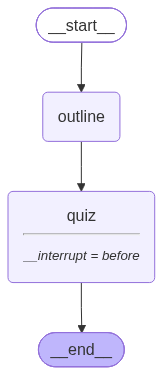

In [32]:
class DebugState(TypedDict, total=False):
    assunto: str
    outline: str
    quiz: str

def node_outline(state: DebugState) -> DebugState:
    assunto = state.get("assunto", "assunto")
    resp = llm.invoke([
        SystemMessage(content="Crie conteúdo em PT-BR, objetivo."),
        HumanMessage(content=f"Crie um outline com 4 tópicos sobre: {assunto}.")
    ])
    return {"outline": resp.content}

def node_quiz(state: DebugState) -> DebugState:
    resp = llm.invoke([
        SystemMessage(content="Crie conteúdo em PT-BR, objetivo."),
        HumanMessage(content=(
            "Crie 2 perguntas de múltipla escolha baseadas no outline abaixo:\n\n"
            f"{state.get('outline','')}\n\n"
            "Não precisa gabarito."
        ))
    ])
    return {"quiz": resp.content}

dbg_builder = StateGraph(DebugState)
dbg_builder.add_node("outline", node_outline)
dbg_builder.add_node("quiz", node_quiz)
dbg_builder.add_edge(START, "outline")
dbg_builder.add_edge("outline", "quiz")
dbg_builder.add_edge("quiz", END)

dbg_checkpointer = MemorySaver()
dbg_graph = dbg_builder.compile(checkpointer=dbg_checkpointer, interrupt_before=["quiz"])
dbg_graph

In [33]:
dbg_config = {"configurable": {"thread_id": "dbg-01"}}

partial = dbg_graph.invoke({"assunto": "Streaming vs updates vs values no LangGraph"}, config=dbg_config)
print("Parou no breakpoint. Estado parcial:")
print(partial)

print("\nContinuando...")
complete = dbg_graph.invoke(None, config=dbg_config)
print("\nEstado final:")
print(complete)

Parou no breakpoint. Estado parcial:
{'assunto': 'Streaming vs updates vs values no LangGraph', 'outline': '**Outline: Streaming\u202f×\u202fUpdates\u202f×\u202fValues no LangGraph**\n\n1. **Conceitos Fundamentais**\n   - Definição de *value* (estado estático) e seu papel nas cadeias de agentes.  \n   - O que são *updates*: mutações incrementais do estado ao longo da execução.  \n   - Introdução ao *streaming*: emissão contínua de dados (texto, eventos, métricas) enquanto o grafo roda.\n\n2. **Quando Usar Cada Estratégia**\n   - **Values** – casos em que o resultado final é suficiente (ex.: geração de um relatório único).  \n   - **Updates** – situações que requerem feedback intermediário ou checkpoints (ex.: loops de raciocínio, refinamento iterativo).  \n   - **Streaming** – fluxos de saída em tempo real (ex.: chat interativo, geração de código passo‑a‑passo, monitoramento de métricas).\n\n3. **Implementação no LangGraph**\n   - Sintaxe básica: `node.value`, `node.update()`, `node.st

In [34]:
#Parte D — Breakpoints dinâmicos

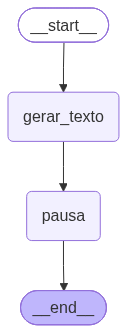

In [35]:
class DynBPState(TypedDict, total=False):
    tema: str
    texto: str
    modo_debug: bool

def node_gerar_texto(state: DynBPState) -> DynBPState:
    tema = state.get("tema", "tema")
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR."),
        HumanMessage(content=f"Escreva uma explicação em até 10 linhas sobre: {tema}.")
    ])
    return {"texto": resp.content}

def node_pausa_condicional(state: DynBPState) -> DynBPState:
    if state.get("modo_debug"):
        interrupt({
            "motivo": "modo_debug ligado",
            "amostra_texto": state.get("texto", "")[:250]
        })
        return {}

    # Heurística extra: se ficar muito grande, também pausa
    if len(state.get("texto", "")) > 900:
        interrupt({"motivo": "texto longo demais", "tamanho": len(state.get("texto",""))})
    return {}

dyn_builder = StateGraph(DynBPState)
dyn_builder.add_node("gerar_texto", node_gerar_texto)
dyn_builder.add_node("pausa", node_pausa_condicional)
dyn_builder.add_edge(START, "gerar_texto")
dyn_builder.add_edge("gerar_texto", "pausa")
dyn_builder.add_edge("pausa", END)

dyn_checkpointer = MemorySaver()
dyn_graph = dyn_builder.compile(checkpointer=dyn_checkpointer)
dyn_graph

In [36]:
#D1) Sem pausa (modo_debug=False)
cfg = {"configurable": {"thread_id": "dyn-01"}}
res = dyn_graph.invoke({"tema": "Quais são os príncipios básicos da computação quântica?", "modo_debug": False}, config=cfg)
print("OK. Não pausou.\n")
print(res["texto"][:500], "...")

OK. Não pausou.

Os princípios básicos da computação quântica são:

1. **Qubit** – unidade de informação que, ao contrário do bit clássico, pode estar simultaneamente em superposição de 0 e 1.  
2. **Superposição** – permite que um qubit represente múltiplos estados ao mesmo tempo, exponenciando o espaço de cálculo.  
3. **Emaranhamento (entrelaçamento)** – correlação forte entre qubits que faz o estado de um depender instantaneamente do estado do outro, mesmo à distância.  
4. **Interferência** – combina amplit ...


In [37]:
#D2) Com pausa (modo_debug=True) e retomada
cfg2 = {"configurable": {"thread_id": "dyn-02"}}
res2 = dyn_graph.invoke({"tema": "Ciência básica da computação quântica", "modo_debug": True}, config=cfg2)

print("Pausou? Payload:")
print(res2.get("__interrupt__"))

print("\nRetomando...")
res2b = dyn_graph.invoke(Command(resume="seguir"), config=cfg2)
print("Concluiu. Texto (amostra):")
print(res2b["texto"][:350], "...")

Pausou? Payload:
[Interrupt(value={'motivo': 'modo_debug ligado', 'amostra_texto': 'A computação quântica estuda como usar propriedades quânticas – superposição, entrelaçamento e interferência – para processar informação.  \nUm **qubit** pode representar 0 e 1 simultaneamente (superposição), permitindo que um algoritmo explore muitas'}, id='6d677c4da759f62be9ff57afb1d3c2af', response_schema=None)]

Retomando...
Concluiu. Texto (amostra):
A computação quântica estuda como usar propriedades quânticas – superposição, entrelaçamento e interferência – para processar informação.  
Um **qubit** pode representar 0 e 1 simultaneamente (superposição), permitindo que um algoritmo explore muitas possibilidades em paralelo.  
Quando qubits são **entrelaçados**, o estado de um afeta instantaneam ...


In [38]:
#Parte E — Editando o estado (feedback humano)

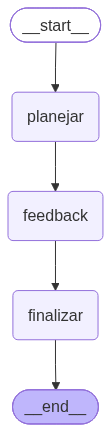

In [39]:
class FeedbackState(TypedDict, total=False):
    tema: str
    nivel: str
    roteiro: str
    versao_final: str

def node_planejar(state: FeedbackState) -> FeedbackState:
    tema = state.get("tema", "tema")
    nivel = state.get("nivel", "iniciante")
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, bem prático."),
        HumanMessage(content=(
            f"Crie um roteiro em 5 tópicos para idéias de criações de Startups {tema}. "
            f"Nível: {nivel}. Inclua 1 exemplo prático."
        ))
    ])
    return {"roteiro": resp.content}

def node_pedir_feedback(state: FeedbackState) -> FeedbackState:
    ajuste = interrupt({
        "pergunta": "Deseja ajustar o nível? (iniciante/intermediário/avançado) ou deixe em branco para manter.",
        "nivel_atual": state.get("nivel", "iniciante")
    })
    if isinstance(ajuste, str) and ajuste.strip():
        return {"nivel": ajuste.strip()}
    return {}

def node_finalizar(state: FeedbackState) -> FeedbackState:
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, com estrutura para apostila."),
        HumanMessage(content=(
            "Transforme o roteiro abaixo em uma versão final formatada:\n\n"
            f"TEMA: {state.get('tema')}\n"
            f"NÍVEL: {state.get('nivel')}\n\n"
            f"ROTEIRO:\n{state.get('roteiro','')}\n\n"
            "Inclua uma seção final: 'Erros comuns' com 3 itens."
        ))
    ])
    return {"versao_final": resp.content}

fb_builder = StateGraph(FeedbackState)
fb_builder.add_node("planejar", node_planejar)
fb_builder.add_node("feedback", node_pedir_feedback)
fb_builder.add_node("finalizar", node_finalizar)

fb_builder.add_edge(START, "planejar")
fb_builder.add_edge("planejar", "feedback")
fb_builder.add_edge("feedback", "finalizar")
fb_builder.add_edge("finalizar", END)

fb_checkpointer = MemorySaver()
fb_graph = fb_builder.compile(checkpointer=fb_checkpointer)
fb_graph

In [40]:
#E1) Rodar até o feedback (interrupt)

In [41]:
fb_config = {"configurable": {"thread_id": "fb-01"}}

part = fb_graph.invoke({"tema": "Time travel no LangGraph", "nivel": "iniciante"}, config=fb_config)
print("Payload do interrupt:")
print(part.get("__interrupt__"))

Payload do interrupt:
[Interrupt(value={'pergunta': 'Deseja ajustar o nível? (iniciante/intermediário/avançado) ou deixe em branco para manter.', 'nivel_atual': 'iniciante'}, id='1b252061c2f532cc03e277759408ad10', response_schema=None)]


In [42]:
#E2) Retomar via resume (ex.: mudar para intermediário)

In [43]:
final_fb = fb_graph.invoke(Command(resume="avançado"), config=fb_config)
print("Nível final:", final_fb.get("nivel"))
print(final_fb["versao_final"][:700], "...")

Nível final: avançado
# **Apostila** – *Time Travel no LangGraph*  
**Nível:** Avançado  
**Público‑alvo:** Desenvolvedores que já conhecem os conceitos básicos de LangGraph e desejam aplicar a ferramenta na geração de ideias de negócios “via viagem no tempo”.  

---  

## Sumário  

1. [Introdução](#introdução)  
2. [Estrutura geral do fluxo (5 tópicos)](#estrutura-geral-do-fluxo-5‑tópicos)  
   1. [Defina o ponto de partida da viagem no tempo](#1️⃣-defina-o-ponto-de-partida-da‑viagem‑no‑tempo)  
   2. [Modele a “máquina de viagem” como agente de LLM](#2️⃣-modele-a‑máquina‑de‑viagem‑como‑agente‑de‑llm)  
   3. [Construa a camada de Ideação de Negócio](#3️⃣-construa-a‑camada‑de‑ideação‑de‑negócio)  
   4. [Crie u ...


In [40]:
#E3) Editar o estado via update_state e continuar

In [41]:
fb_config2 = {"configurable": {"thread_id": "fb-02"}}

# 1) para no feedback
fb_graph.invoke({"tema": "Breakpoints dinâmicos", "nivel": "iniciante"}, config=fb_config2)

# 2) mostra o estado atual
state_now = fb_graph.get_state(fb_config2)
print("Estado antes da edição:")
print(state_now.values)

# 3) atualiza o estado (correção humana)
new_cfg = fb_graph.update_state(
    fb_config2,
    values={"nivel": "avançado", "tema": "Breakpoints dinâmicos (com casos reais)"}
)

print("\nConfig retornado por update_state:", new_cfg)

# 4) continua a execução
cfg_to_use = new_cfg if new_cfg is not None else fb_config2
done = fb_graph.invoke(None, config=cfg_to_use)

print("\nEstado final (amostra):")
print("tema:", done.get("tema"))
print("nivel:", done.get("nivel"))
print(done.get("versao_final", "")[:600], "...")

Estado antes da edição:
{'tema': 'Breakpoints dinâmicos', 'nivel': 'iniciante', 'roteiro': '**Aula: Breakpoints Dinâmicos – Como criar layouts responsivos que se adaptam de verdade**  \n*Público:* Iniciantes em desenvolvimento front‑end  \n*Duração sugerida:* 45\u202fmin a 1\u202fh  \n\n---\n\n## 1️⃣ Introdução – O que são breakpoints e por que “dinâmicos”?\n\n| Conceito | Explicação simples |\n|----------|-------------------|\n| **Breakpoint tradicional** | Ponto fixo (ex.: `@media (max‑width: 768px)`) onde o layout muda de forma abrupta. |\n| **Problema** | Em telas muito próximas ao ponto de corte, o conteúdo pode ficar “cortado” ou “espremido”. |\n| **Breakpoint dinâmico** | Valor que varia de acordo com a largura da viewport, permitindo transições suaves e fluidas. |\n| **Benefício** | Menos “saltos” visuais, design mais consistente em dispositivos com resoluções intermediárias (ex.: tablets 9‑10\u202fpolegadas, telas de laptop 1366\u202fpx, etc.). |\n\n> **Metáfora:** Pense nos b

In [44]:
#Parte F — Time travel (viagem no tempo)
#listar checkpoints;
#voltar a um checkpoint antigo;
#alterar o estado naquele ponto;
#e continuar gerando um novo futuro (fork).

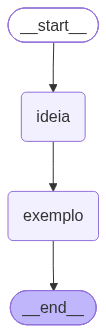

In [45]:
class TravelState(TypedDict, total=False):
    ideia: str
    exemplo: str

def node_ideia(state: TravelState) -> TravelState:
    resp = llm.invoke([
        SystemMessage(content="Responda em PT-BR, curto e claro."),
        HumanMessage(content="Gere uma ideia de uso (1 frase) para usar LangGraph em uma Startup de IA.")
    ])
    return {"ideia": resp.content.strip()}

def node_exemplo(state: TravelState) -> TravelState:
    resp = llm.invoke([
        SystemMessage(content="Responda em PT-BR, curto e claro."),
        HumanMessage(content=(
            "Crie um exemplo prático modelo de Startups de IA, de acordo com a ideia abaixo.\n"
            f"IDEIA: {state.get('ideia','')}\n"
            "Formato: 6-10 linhas, com bullets."
        ))
    ])
    return {"exemplo": resp.content}

travel_builder = StateGraph(TravelState)
travel_builder.add_node("ideia", node_ideia)
travel_builder.add_node("exemplo", node_exemplo)
travel_builder.add_edge(START, "ideia")
travel_builder.add_edge("ideia", "exemplo")
travel_builder.add_edge("exemplo", END)

travel_checkpointer = MemorySaver()
travel_graph = travel_builder.compile(checkpointer=travel_checkpointer)
travel_graph

In [47]:
#F1) Execução normal

In [48]:
t_cfg = {"configurable": {"thread_id": "travel-01"}}

original = travel_graph.invoke({}, config=t_cfg)
print("IDEIA ORIGINAL:", original.get("ideia"))
print("\nEXEMPLO ORIGINAL:\n", original.get("exemplo"))

IDEIA ORIGINAL: Utilize o LangGraph para criar fluxos dinâmicos de agentes de IA que personalizam recomendações de produtos em tempo real, integrando dados de comportamento do usuário, histórico de compras e tendências de mercado.

EXEMPLO ORIGINAL:
 - **Nome da startup:** Recomenda.ai  
- **Problema:** E‑commerces perdem vendas por recomendações genéricas e lentas.  
- **Solução:** Usa LangGraph para orquestrar agentes de IA que combinam dados de comportamento em tempo real, histórico de compras e tendências de mercado, gerando sugestões hiperpersonalizadas.  
- **Arquitetura:** *Agent Collector* captura cliques e tempo de navegação; *Agent Profiler* atualiza o perfil do usuário; *Agent Trend* consome APIs de tendências; *Agent Recommender* gera a lista de produtos.  
- **Fluxo dinâmico:** Se o usuário visita categorias novas, o *Agent Collector* dispara o *Agent Profiler* para re‑pesar interesses e o *Agent Recommender* recalcula a oferta em < 200 ms.  
- **Monetização:** Modelo SaaS

In [49]:
history = list(travel_graph.get_state_history(t_cfg))
print("Quantidade de checkpoints:", len(history))

for i, st in enumerate(history[:6]):
    checkpoint_id = st.config["configurable"].get("checkpoint_id")
    print(f"{i}: next={st.next} | checkpoint_id={checkpoint_id} | keys={list(st.values.keys())}")

Quantidade de checkpoints: 4
0: next=() | checkpoint_id=1f1d485a-71b2-696c-8002-3070e50d0cb5 | keys=['ideia', 'exemplo']
1: next=('exemplo',) | checkpoint_id=1f1d485a-67d1-65a2-8001-9f2115fdd7b0 | keys=['ideia']
2: next=('ideia',) | checkpoint_id=1f1d485a-6189-6d3d-8000-324276e4aeb8 | keys=[]
3: next=('__start__',) | checkpoint_id=1f1d485a-6187-665e-bfff-4ca777df19fc | keys=[]


In [50]:
#F3) Fork: alterando o passado e criando novo futuro
#Dica: normalmente history[1] é um ponto anterior ao último nó (dependendo da versão).

In [53]:
selected = history[1]  # ajuste se necessário
print("Selecionado next:", selected.next)
print("Values naquele ponto:", selected.values)

new_config = travel_graph.update_state(
    selected.config,
    values={"ideia": "LIstar projetos reais de SLMs em Startups"}
)

cfg_to_use = new_config if new_config is not None else selected.config
fork = travel_graph.invoke(None, config=cfg_to_use)

print("\n--- FUTURO (FORK) ---")
print("IDEIA:", fork.get("ideia"))
print("EXEMPLO:\n", fork.get("exemplo"))

Selecionado next: ('exemplo',)
Values naquele ponto: {'ideia': 'Utilize o LangGraph para criar fluxos dinâmicos de agentes de IA que personalizam recomendações de produtos em tempo real, integrando dados de comportamento do usuário, histórico de compras e tendências de mercado.'}

--- FUTURO (FORK) ---
IDEIA: LIstar projetos reais de SLMs em Startups
EXEMPLO:
 - **ChatFit** – desenvolve um SLM especializado em planos de treinamento personalizados, integrando dados de wearables e feedback em tempo real.  
- **LegalAI** – SLM focado em análise de contratos, automatizando a extração de cláusulas e sugestões de revisão jurídica.  
- **EduBot** – modelo de linguagem leve para tutoria virtual em escolas, adaptando explicações ao nível de cada aluno.  
- **HealthAssist** – SLM que interpreta prontuários eletrônicos e gera relatórios de diagnóstico preliminar para clínicas de pequeno porte.  
- **RetailSense** – modelo otimizado para recomendações de produtos em e‑commerces, operando em edge p

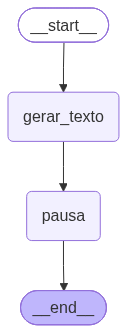

In [70]:
import re

PALAVRAS_CHAVE = {"Startups", "IA", "LAnggraph"}

def node_pausa_condicional(state: DynBPState) -> DynBPState:
    texto = state.get("texto", "")

    if state.get("modo_debug"):
        interrupt({
            "motivo": "modo_debug ligado",
            "amostra_texto": texto[:250],
        })
        return {}

    palavras = set(re.findall(r"\w+", texto.casefold()))
    encontradas = sorted(PALAVRAS_CHAVE & palavras)

    if encontradas:
        interrupt({
            "motivo": "palavras-chave detectadas",
            "palavras_encontradas": encontradas,
            "amostra_texto": texto[:250],
        })

    return {}
dyn_builder = StateGraph(DynBPState)
dyn_builder.add_node("gerar_texto", node_gerar_texto)
dyn_builder.add_node("pausa", node_pausa_condicional)
dyn_builder.add_edge(START, "gerar_texto")
dyn_builder.add_edge("gerar_texto", "pausa")
dyn_builder.add_edge("pausa", END)

dyn_checkpointer = MemorySaver()
dyn_graph = dyn_builder.compile(checkpointer=dyn_checkpointer)
dyn_graph

In [73]:
cfg2 = {"configurable": {"thread_id": "dyn-02"}}
res2 = dyn_graph.invoke({"tema": "Startups, IA, Langgraph", "modo_debug": True}, config=cfg2)

res2b = dyn_graph.invoke(Command(resume="seguir"), config=cfg2)
print("Concluiu. Texto (amostra):")
print(res2b["texto"][:450], "...")

Concluiu. Texto (amostra):
Startups são empresas emergentes que buscam crescer rápido, geralmente com modelos de negócio inovadores e financiamento de investidores‑anjos ou venture capital.  
Inteligência Artificial (IA) refere‑se a sistemas computacionais capazes de aprender, raciocinar e tomar decisões a partir de grandes volumes de dados, automatizando tarefas complexas.  
LangGraph é uma biblioteca de código aberto que facilita a criação de fluxos de trabalho (graph‑ba ...


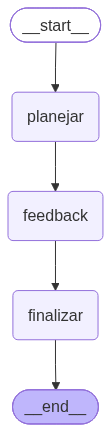

In [11]:
class FeedbackState(TypedDict, total=False):
    tema: str
    nivel: str
    roteiro: str
    pedido: str
    versao_final: str


def node_planejar(state: FeedbackState) -> FeedbackState:
    tema = state.get("tema", "tema")
    nivel = state.get("nivel", "iniciante")

    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, bem didático."),
        HumanMessage(content=(
            f"Crie um roteiro em 5 tópicos para uma aula sobre {tema}. "
            f"Nível: {nivel}. Inclua 1 exemplo prático."
        )),
    ])
    return {"roteiro": resp.content}


def node_pedir_feedback(state: FeedbackState) -> FeedbackState:
    novo_nivel = interrupt({
        "pergunta": (
            "Qual nível deseja? iniciante/intermediário/avançado. "
            "Deixe em branco para manter."
        ),
        "nivel_atual": state.get("nivel", "iniciante"),
    })

    nivel = state.get("nivel", "iniciante")
    if isinstance(novo_nivel, str) and novo_nivel.strip():
        nivel = novo_nivel.strip()

    tema = state.get("tema", "tema")

    while True:
        novo_tema = interrupt({
            "pergunta": "Qual tema deseja? Deixe em branco para manter.",
            "tema_atual": tema,
        })

        if isinstance(novo_tema, str) and novo_tema.strip():
            tema = novo_tema.strip()

        confirmacao = interrupt({
            "pergunta": f"Tem certeza do tema '{tema}'? Responda yes ou no.",
            "tema": tema,
        })

        while str(confirmacao).strip().casefold() not in {"yes", "no"}:
            confirmacao = interrupt({
                "pergunta": "Resposta inválida. Responda yes ou no.",
                "tema": tema,
            })

        if str(confirmacao).strip().casefold() == "yes":
            return {"nivel": nivel, "tema": tema}


def node_finalizar(state: FeedbackState) -> FeedbackState:
    resp = llm.invoke([
        SystemMessage(
            content="Escreva em PT-BR, com estrutura para apostila."
        ),
        HumanMessage(content=(
            "Transforme o roteiro abaixo em uma versão final formatada.\n"
            "Adapte o conteúdo ao nível informado e atenda ao pedido "
            "adicional do humano.\n\n"
            f"TEMA: {state.get('tema')}\n"
            f"NÍVEL: {state.get('nivel')}\n\n"
            f"ROTEIRO:\n{state.get('roteiro', '')}\n\n"
            f"PEDIDO ADICIONAL: {state.get('pedido') or 'Nenhum.'}\n\n"
            "Inclua uma seção final: 'Erros comuns' com 3 itens."
        )),
    ])
    return {"versao_final": resp.content}


fb_builder = StateGraph(FeedbackState)
fb_builder.add_node("planejar", node_planejar)
fb_builder.add_node("feedback", node_pedir_feedback)
fb_builder.add_node("finalizar", node_finalizar)

fb_builder.add_edge(START, "planejar")
fb_builder.add_edge("planejar", "feedback")
fb_builder.add_edge("feedback", "finalizar")
fb_builder.add_edge("finalizar", END)

fb_checkpointer = MemorySaver()
fb_graph = fb_builder.compile(checkpointer=fb_checkpointer)
fb_graph

In [ ]:
fb_config = {"configurable": {"thread_id": "fb-tres-nos-01"}}

parcial = fb_graph.invoke(
    {"tema": "Streaming no LangGraph", "nivel": "iniciante"},
    config=fb_config,
)
print(parcial.get("__interrupt__"))

[Interrupt(value={'pergunta': 'Qual nível deseja? iniciante/intermediário/avançado. Deixe em branco para manter.', 'nivel_inicial': 'iniciante'}, id='3f15e0f056d3b7380963533703f30a68', response_schema=None)]


In [135]:
final_fb = fb_graph.invoke(Command(resume="avançado"), config=fb_config)
print("Nível atualizado:", final_fb.get("nivel"))
print("Payload do interrupt:")
print(part.get("__interrupt__"))

Nível atualizado: avançado
Payload do interrupt:
[Interrupt(value={'pergunta': 'Qual nível deseja? iniciante/intermediário/avançado. Deixe em branco para manter.', 'nivel_atual': 'iniciante'}, id='3f0ee46b56573c7a26595110fee095ec', response_schema=None)]


In [136]:
parcial = fb_graph.invoke(
    Command(resume="Computação Quântica em processamentos comparados com GPU"),
    config=fb_config,
)
print("Payload do interrupt:")
print(parcial.get("__interrupt__"))


Payload do interrupt:
[Interrupt(value={'pergunta': "Confirma usar o tema 'Computação Quântica em processamentos comparados com GPU'? Responda yes para confirmar ou no para manter o original.", 'tema_original': 'Streaming no LangGraph', 'tema_proposto': 'Computação Quântica em processamentos comparados com GPU'}, id='b90cd05a1a6ff4d6b693b0cfe95e5228', response_schema=None)]


In [137]:
# Confirma o tema e gera o material.
final = fb_graph.invoke(
    Command(resume="yes"),
    config=fb_config,
)
print("Nível:", final["nivel"])
print("Tema:", final["tema"])
print(final["versao_final"])

Nível: avançado
Tema: Computação Quântica em processamentos comparados com GPU
# Apostila  
## Computação Quântica × Processamento em GPU  
### Nível Avançado  

**Carga horária sugerida:** 2 h (120 min)  
**Objetivo geral:** Capacitar o estudante a comparar criticamente os paradigmas de paralelismo clássico (CPU/GPU) e quântico, identificar nichos de vantagem de cada tecnologia e projetar soluções híbridas que explorem o melhor dos dois mundos.  

---  

## Sumário  

1. [Introdução comparativa: paradigma clássico, GPU e computação quântica](#1-introdução-comparativa)  
2. [Fundamentos teóricos da computação quântica relevantes para comparação](#2-fundamentos-teóricos)  
3. [Algoritmos de referência: GPU‑friendly vs Quantum‑advantage](#3-algoritmos-de-referência)  
4. [Exemplo prático – Grover Search em CUDA e Qiskit](#4-exemplo-prático)  
5. [Perspectivas, desafios e roadmap de integração](#5-perspectivas)  
6. [Erros comuns ao trabalhar com GPU e QC](#6-erros-comuns)  
7. [Materiais

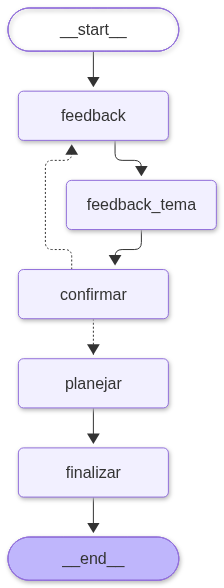

In [48]:
from typing import TypedDict, Literal

from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command


class FeedbackState(TypedDict, total=False):
    tema: str
    nivel: str
    roteiro: str
    versao_final: str

def node_pedir_feedback(state: FeedbackState) -> FeedbackState:
    resposta = interrupt({
        "pergunta": (
            "Qual nível deseja? iniciante/intermediário/avançado. "
            "Deixe em branco para manter."
        ),
        "nivel_atual": state.get("nivel", "iniciante"),
    })

    if isinstance(resposta, str) and resposta.strip():
        return {"nivel": resposta.strip()}

    return {}


def node_feedback_tema(state: FeedbackState) -> FeedbackState:
    resposta = interrupt({
        "pergunta": "Deseja mudar de tema? Deixe em branco para manter.",
        "tema_atual": state.get("tema", ""),
    })

    if isinstance(resposta, str) and resposta.strip():
        return {"tema": resposta.strip()}

    return {}
    
def node_planejar(state: FeedbackState) -> FeedbackState:
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, bem didático."),
        HumanMessage(content=(
            f"Crie um roteiro em 5 tópicos sobre {state.get('tema', 'LangGraph')}. "
            f"Nível: {state.get('nivel', 'iniciante')}. "
            "Inclua 1 exemplo prático."
        )),
    ])
    return {"roteiro": resp.content}

def node_confirmar(
    state: FeedbackState,
) -> Command[Literal["planejar", "feedback"]]:
    pergunta = {
        "pergunta": (
            "Confirma o tema e o nível? "
            "Responda yes para gerar o material ou no para editar novamente."
        ),
        "tema": state.get("tema", ""),
        "nivel": state.get("nivel", "iniciante"),
    }

    resposta = interrupt(pergunta)

    while str(resposta).strip().casefold() not in {"yes", "no"}:
        resposta = interrupt({
            **pergunta,
            "erro": "Resposta inválida. Digite yes ou no.",
        })

    if str(resposta).strip().casefold() == "yes":
        return Command(goto="planejar")

    return Command(goto="feedback")

def node_finalizar(state: FeedbackState) -> FeedbackState:
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, com estrutura para apostila."),
        HumanMessage(content=(
            "Transforme o roteiro em uma versão final formatada.\n\n"
            f"TEMA: {state.get('tema', '')}\n"
            f"NÍVEL: {state.get('nivel', 'iniciante')}\n"
            f"ROTEIRO:\n{state.get('roteiro', '')}\n\n"
            "Inclua uma seção 'Erros comuns' com 3 itens."
        )),
    ])
    return {"versao_final": resp.content}


fb_builder = StateGraph(FeedbackState)

fb_builder.add_node("feedback", node_pedir_feedback)
fb_builder.add_node("feedback_tema", node_feedback_tema)
fb_builder.add_node("confirmar", node_confirmar)
fb_builder.add_node("planejar", node_planejar)
fb_builder.add_node("finalizar", node_finalizar)

fb_builder.add_edge(START, "feedback")
fb_builder.add_edge("feedback", "feedback_tema")
fb_builder.add_edge("feedback_tema", "confirmar")
fb_builder.add_edge("planejar", "finalizar")
fb_builder.add_edge("finalizar", END)

fb_checkpointer = MemorySaver()
fb_graph = fb_builder.compile(checkpointer=fb_checkpointer)
fb_graph

In [70]:
fb_config = {"configurable": {"thread_id": "fb-confirmacao-01"}}

resultado = fb_graph.invoke(
    {"tema": "LangGraph", "nivel": "iniciante"},
    config=fb_config,
)

while resultado.get("__interrupt__"):
    pausa = resultado["__interrupt__"][0]

    for chave, valor in pausa.value.items():
        print(f"{chave}: {valor}")

    resposta = input("\nSua resposta: ")

    resultado = fb_graph.invoke(
        Command(resume=resposta),
        config=fb_config,
    )

from IPython.display import clear_output, display, Markdown

clear_output(wait=True)

print("Nível:", resultado["nivel"])
print("Tema:", resultado["tema"])

display(Markdown(resultado["versao_final"]))

Nível: avançado
Tema: Computação Quântica


# Apostila – Computação Quântica (Nível Avançado)  
**Formato:** PDF/Impressão – 5 capítulos + material de apoio  

---

## Sumário  

1. **Fundamentos Matemáticos e Físicos da Informação Quântica**  
2. **Modelos de Computação Quântica**  
3. **Algoritmos Quânticos de Vantagem Exponencial**  
4. **Arquiteturas e Tecnologias de Hardware**  
5. **Exemplo Prático – Implementação do Algoritmo de Shor para Fatorar 15**  
6. **Erros Comuns**  
7. **Bibliografia e Recursos Complementares**  
8. **Próximos Passos Sugeridos**  

---  

## 1️⃣ Fundamentos Matemáticos e Físicos da Informação Quântica  

| **Subtópico** | **Conteúdo essencial** | **Por que é crucial?** |
|---|---|---|
| **1.1 Vetores de estado (ket) e espaço de Hilbert** | • Definição de \|ψ⟩ ∈ ℂⁿ  <br>• Produto interno, ortogonalidade, normalização | Base para representar qubits e sistemas multi‑qubit. |
| **1.2 Operadores lineares e unitários** | • Matrizes 2×2 (Pauli, Hadamard, fase) <br>• Decomposição de operadores (Euler, QR) | Descrevem evoluções físicas (portas lógicas). |
| **1.3 Medição e colapso de estado** | • Operadores de projeção <br>• Probabilidades  p = |⟨φ|ψ⟩|² <br>• Pós‑medição (estado colapsado) | Conecta a teoria ao resultado observável. |
| **1.4 Emaranhamento e correlação quântica** | • Estados de Bell, GHZ <br>• Medidas de entanglement (concurrence, entropia de von Neumann) | Recurso essencial para vantagem quântica. |
| **1.5 Teorema de No‑Cloning e limites da informação** | • Prova formal <br>• Implicações para criptografia | Fundamenta a segurança de protocolos quânticos. |

> **Leitura recomendada:** Nielsen & Chuang – *Quantum Computation and Quantum Information*, capítulos 1‑3.  

---  

## 2️⃣ Modelos de Computação Quântica  

| **Modelo** | **Principais características** | **Quando usar** |
|---|---|---|
| **2.1 Circuito quântico (gate model)** | Portas unitárias sequenciais, medição ao final. | Algoritmos padrão (Shor, Grover). |
| **2.2 Computação adiabática / Quantum Annealing** | Evolução lenta do Hamiltoniano, busca do estado fundamental. | Otimização combinatória, problemas de Ising. |
| **2.3 Topological quantum computing** | Quasipartículas anyônicas, braiding, resistência a erros. | Futuro de hardware tolerante a falhas. |
| **2.4 Modelo de medição‑baseada (MBQC)** | Cluster states, computação via medições adaptativas. | Estudos de complexidade, demonstrações de universalidade. |

> **Atividade prática:** Desenhar um circuito simples (Hadamard + CNOT) e identificar o estado resultante (Bell state).  

---  

## 3️⃣ Algoritmos Quânticos de Vantagem Exponencial  

| **Algoritmo** | **Problema resolvido** | **Complexidade (clássica vs quântica)** |
|---|---|---|
| **3.1 Algoritmo de Shor** | Fatoração de inteiros (RSA) | O(e^{n^{1/3}}) → O((log N)³) (tempo polinomial) |
| **3.2 Algoritmo de Grover** | Busca não estruturada em lista N | O(√N) vs. O(N) |
| **3.3 Algoritmo HHL** (Harow‑Hassidim‑Lloyd) | Solução de sistemas lineares A x = b | Log‑polinomial em dimensão (para matrizes esparsas) |
| **3.4 Simulação de Hamiltonianos** | Evolução de sistemas quânticos (química, materiais) | Exponencialmente mais rápido para certos casos. |

> **Dica de estudo:** Implementar Grover em simuladores (Qiskit ou Cirq) para observar a amplificação de amplitude.  

---  

## 4️⃣ Arquiteturas e Tecnologias de Hardware  

| **Tecnologia** | **Qubit** | **Controle / Leitura** | **Principais desafios** |
|---|---|---|---|
| **4.1 Supercondutores** (IBM, Google, Rigetti) | Circuitos Josephson | Pulsos de micro‑ondas, leitura dispersiva | Coerência ~100 µs; escalabilidade de interconexões. |
| **4.2 Íons aprisionados** (IonQ, Honeywell) | Íons de Yb⁺, Ca⁺ | Lasers de alta precisão, fluorescência | Fidelidade > 99,9 %; taxa de portas mais lenta. |
| **4.3 Fotônica** (PsiQuantum, Xanadu) | Fótons em guias de onda | Interferômetros, detectores SNSPD | Integração de milhares de modos; correção de perdas. |
| **4.4 Spin em pontos quânticos** (Microsoft) | Elétrons em semicondutores | Controle elétrico, leitura por sensor de carga | Compatibilidade CMOS; coerência ainda limitada. |
| **4.5 Tecnologias emergentes** (NV‑centers, topológicos) | Defeitos de cristal, anyons | Controle por micro‑ondas, leitura óptica | Promessa de tolerância a erros; fase de prova de conceito. |

> **Exercício:** Compare a taxa de erro de porta (gate error) e o tempo de coerência (T₁/T₂) entre duas plataformas e discuta como isso impacta a profundidade de circuitos realizáveis.  

---  

## 5️⃣ Exemplo Prático – Implementação do Algoritmo de Shor para Fatorar 15  

### 5.1 Visão geral do algoritmo  

1. **Escolha aleatória de a** – 2 ≤ a < N (N = 15).  
2. **Teste de coprimalidade** – `gcd(a,N)`; se > 1 já temos um fator.  
3. **Estimativa de fase quântica** – Quantum Phase Estimation (QPE) para obter o período *r* de *aᵏ mod N*.  
4. **Obtenção dos fatores** – Se *r* for par, calcular `gcd(a^{r/2} ± 1, N)`.  

### 5.2 Preparação do ambiente (Python + Qiskit)

```python
# 1️⃣ Instalação (executar apenas se Qiskit ainda não estiver instalado)
!pip install qiskit --quiet

# 2️⃣ Importações
from qiskit import QuantumCircuit, Aer, execute
from qiskit.circuit.library import QFT
from qiskit.visualization import plot_histogram
import numpy as np
import math
from math import gcd
```

### 5.3 Funções auxiliares  

```python
def modular_exp(a, power, N):
    """a^power mod N – exponenciação rápida."""
    result = 1
    a = a % N
    while power:
        if power & 1:
            result = (result * a) % N
        a = (a * a) % N
        power >>= 1
    return result


def get_period(a, N, n_count):
    """
    Monta o circuito de estimativa de fase para encontrar o período r.
    n_count = número de qubits de controle (≈ 2·log₂N).
    """
    qc = QuantumCircuit(n_count + 1, n_count)   # +1 qubit de alvo
    qc.x(n_count)                               # prepara |1> no alvo
    # Hadamard nos qubits de controle
    for q in range(n_count):
        qc.h(q)

    # Operador modular exponencial controlado
    for q in range(n_count):
        exponent = 2**(n_count - q - 1)          # 2^{k}
        # U_a^{2^k} = |x⟩ → |a^{2^k}·x mod N⟩
        # Implementação simplificada usando portas de fase (CP)
        angle = 2 * np.pi * modular_exp(a, exponent, N) / N
        qc.cp(angle, q, n_count)

    # QFT inversa
    qc.append(QFT(num_qubits=n_count, inverse=True, do_swaps=False), range(n_count))

    # Medição
    qc.measure(range(n_count), range(n_count))
    return qc
```

### 5.4 Execução no simulador (exemplo com a = 2)

```python
N = 15
a = 2
n_count = 4                     # 2ⁿ ≈ N² → 4 qubits de controle são suficientes

qc = get_period(a, N, n_count)

# Simulador ruidoso (pode-se substituir por um NoiseModel realista)
backend = Aer.get_backend('qasm_simulator')
result = execute(qc, backend=backend, shots=4096).result()
counts = result.get_counts()
plot_histogram(counts, title='Distribuição de fases (a = 2)')
```

### 5.5 Processamento clássico dos resultados  

```python
# 1️⃣ Valor medido mais frequente
measured = max(counts, key=counts.get)
phase = int(measured, 2) / 2**n_count          # fase ∈ [0,1)

# 2️⃣ Aproximação de fração usando continuação de frações
from fractions import Fraction
fraction = Fraction(phase).limit_denominator(N)
r = fraction.denominator

print(f"Fase estimada: {phase:.4f} → r ≈ {r}")

# 3️⃣ Cálculo dos fatores (se r for par)
if r % 2 == 0:
    x = modular_exp(a, r//2, N)
    f1 = gcd(x-1, N)
    f2 = gcd(x+1, N)
    print(f"Possíveis fatores: {f1}, {f2}")
else:
    print("Período r ímpar – nova tentativa necessária.")
```

#### Resultado esperado (circuito ideal)

```
Fase estimada: 0.5000 → r ≈ 4
Possíveis fatores: 3, 5
```

### 5.6 Pontos críticos a observar  

| **Etapa** | **Dificuldade prática** | **Como mitigar** |
|---|---|---|
| **Escolha de a** | `gcd(a,N) ≠ 1` pode gerar fatores triviais ou falhas. | Testar vários valores de *a* até obter coprimalidade. |
| **Precisão de QPE** | Poucos qubits de controle ⇒ resolução de fase limitada → *r* impreciso. | Aumentar `n_count` (≥ 2·log₂N) ou usar “phase kick‑back” com registradores auxiliares. |
| **Ruído e decoerência** | Portas controladas (CP) são sensíveis; distribuição de resultados espalhada. | Usar hardware de alta fidelidade, aplicar técnicas de mitigação de erro (readout error mitigation, zero‑noise extrapolation). |
| **Racionalização da fração** | A continuação de frações pode devolver múltiplos de *r*. | Verificar `a**r % N == 1`; caso contrário, dividir *r* pelos seus fatores comuns. |

> **Conclusão:** Mesmo para N = 15 o algoritmo evidencia os gargalos reais (precisão de fase, ruído, número de tentativas). Escalar para N com dezenas de dígitos exige milhares de qubits lógicos e códigos de correção de erro ainda em desenvolvimento.  

---  

## 6️⃣ Erros Comuns (e como evitá‑los)

| **#** | **Erro frequente** | **Por que acontece** | **Correção / Boa prática** |
|---|---|---|---|
| 1 | **Usar número insuficiente de qubits de controle em QPE** | A resolução da fase é 1/2^{n\_count}; poucos bits dão estimativas grosseiras. | Sempre escolher `n_count ≥ 2·log₂ N`. Teste a convergência aumentando gradualmente. |
| 2 | **Ignorar a necessidade de coprimalidade entre *a* e *N*** | `gcd(a,N) > 1` devolve um fator trivial antes da fase quântica, mas pode levar a “falso sucesso”. | Calcule `gcd(a,N)` antes de montar o circuito; se > 1, registre o fator e reinicie com outro *a*. |
| 3 | **Não tratar o ruído de leitura** | Medições em hardware real apresentam viés (bias) que distorcem a distribuição de fases. | Aplique *readout error mitigation* (matriz de confusão) ou execute o mesmo circuito em um simulador ruidoso para calibrar. |

---  

## 7️⃣ Bibliografia e Recursos Complementares

In [43]:
fb_config = {"configurable": {"thread_id": "fb-celulas-01"}}

resultado = fb_graph.invoke(
    {"tema": "LangGraph", "nivel": "iniciante"},
    config=fb_config,
)

print(resultado["__interrupt__"][0].value)

{'pergunta': 'Qual nível deseja? iniciante/intermediário/avançado. Deixe em branco para manter.', 'nivel_atual': 'iniciante'}


In [44]:
nivel = input("Nível desejado (Enter para manter): ")

resultado = fb_graph.invoke(
    Command(resume=nivel),
    config=fb_config,
)

print(resultado["__interrupt__"][0].value)

{'pergunta': 'Deseja mudar de tema? Deixe em branco para manter.', 'tema_atual': 'LangGraph'}


In [45]:
tema = input("Tema desejado (Enter para manter): ")

resultado = fb_graph.invoke(
    Command(resume=tema),
    config=fb_config,
)

print(resultado["__interrupt__"][0].value)

{'pergunta': 'Confirma o tema e o nível? Responda yes para gerar o material ou no para editar novamente.', 'tema': 'Computação Quântica', 'nivel': 'avançado'}


In [47]:
confirmacao = input("Confirma o tema e o nível? (yes/no): ").strip().casefold()

while confirmacao not in {"yes", "no"}:
    confirmacao = input("Digite yes ou no: ").strip().casefold()

resultado = fb_graph.invoke(
    Command(resume=confirmacao),
    config=fb_config,
)

if resultado.get("__interrupt__"):
    print(resultado["__interrupt__"][0].value)
    print("\nExecute novamente as células 2, 3 e 4.")
else:
    print("Nível:", resultado["nivel"])
    print("Tema:", resultado["tema"])
    print(resultado["versao_final"])

Nível: avançado
Tema: Computação Quântica
# Apostila de Computação Quântica – Nível Avançado  
**Autor:** [Seu Nome] – Departamento de Física/Computação  
**Data:** 2026‑10‑31  

---  

## Sumário  

1. [Fundamentos Matemáticos da Informação Quântica](#1-fundamentos-matemáticos-da-informação-quântica)  
2. [Modelos de Computação Quântica](#2-modelos-de-computação-quântica)  
3. [Algoritmos Quânticos de Referência](#3-algoritmos-quânticos-de-referência)  
4. [Correção de Erros e Tolerância a Falhas](#4-correção-de-erros-e-tolerância-a-falhas)  
5. [Exemplo Prático – VQE para a Molécula H₂](#5-exemplo-prático---vqe-para-a-molécula-h₂)  
6. [Erros Comuns ao Trabalhar com Computação Quântica](#6-erros-comuns-ao-trabalhar-com-computação-quântica)  
7. [Bibliografia Recomendada](#7-bibliografia-recomendada)  

---  

## 1️⃣ Fundamentos Matemáticos da Informação Quântica  

| Subtópico | Conteúdo‑chave | Dicas didáticas |
|-----------|----------------|-----------------|
| **1.1 Espaço de Hilb

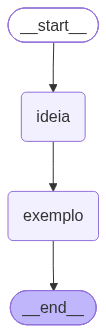

In [62]:
class TravelState(TypedDict, total=False):
    ideia: str
    exemplo: str

def node_ideia(state: TravelState) -> TravelState:
    resp = llm.invoke([
        SystemMessage(content="Responda em PT-BR, curto e claro."),
        HumanMessage(content="Gere uma ideia de exemplo prático (1 frase) para ensinar conceitos moeda quântica.")
    ])
    return {"ideia": resp.content.strip()}

def node_exemplo(state: TravelState) -> TravelState:
    resp = llm.invoke([
        SystemMessage(content="Responda em PT-BR, curto e claro."),
        HumanMessage(content=(
            "Crie um exemplo prático de sala de aula usando a ideia abaixo.\n"
            f"IDEIA: {state.get('ideia','')}\n"
            "Formato: 6-10 linhas, com bullets."
        ))
    ])
    return {"exemplo": resp.content}

travel_builder = StateGraph(TravelState)
travel_builder.add_node("ideia", node_ideia)
travel_builder.add_node("exemplo", node_exemplo)
travel_builder.add_edge(START, "ideia")
travel_builder.add_edge("ideia", "exemplo")
travel_builder.add_edge("exemplo", END)

travel_checkpointer = MemorySaver()
travel_graph = travel_builder.compile(checkpointer=travel_checkpointer)
travel_graph

In [63]:
t_cfg = {"configurable": {"thread_id": "travel-01"}}

original = travel_graph.invoke({}, config=t_cfg)

print("IDEIA:", original["ideia"])
print("EXEMPLO:\n", original["exemplo"])

IDEIA: Lance uma moeda virtual que, ao ser "virada", colapsa instantaneamente para cara ou coroa apenas quando o usuário a observa no aplicativo.
EXEMPLO:
 - **Objetivo:** Demonstrar conceitos de superposição e colapso de estado da mecânica quântica.  
- **Ferramenta:** App de realidade aumentada que exibe uma moeda virtual em superposição (girando).  
- **Procedimento:** Cada aluno abre o app e vê a moeda “flutuando” sem definição de cara ou coroa.  
- **Ação:** Ao tocar na tela (observar), a moeda colapsa instantaneamente para cara ou coroa.  
- **Registro:** O aluno anota o resultado e o instante da observação.  
- **Discussão:** Comparar a aleatoriedade do colapso com lançamentos de moedas reais e discutir a influência do observador.  
- **Avaliação:** Perguntas curtas sobre por que a moeda só define um lado ao ser observada.


In [68]:
history = list(travel_graph.get_state_history(t_cfg))
print("Quantidade de checkpoints:", len(history))

for i, st in enumerate(history[:6]):
    checkpoint_id = st.config["configurable"].get("checkpoint_id")
    print(f"{i}: next={st.next} | checkpoint_id={checkpoint_id} | keys={list(st.values.keys())}")

Quantidade de checkpoints: 12
0: next=() | checkpoint_id=1f1d512e-98dd-6e94-8004-bc9319940d3d | keys=['ideia', 'exemplo']
1: next=('exemplo',) | checkpoint_id=1f1d512e-914a-64c5-8003-ddd359f6ca8c | keys=['ideia']
2: next=() | checkpoint_id=1f1d512e-9147-6d4a-8004-08481112c723 | keys=['ideia', 'exemplo']
3: next=('exemplo',) | checkpoint_id=1f1d512e-8805-6bf5-8003-c75282068f62 | keys=['ideia']
4: next=() | checkpoint_id=1f1d5124-8f47-699c-8003-353ca9f21bbb | keys=['ideia', 'exemplo']
5: next=('exemplo',) | checkpoint_id=1f1d5124-867a-68f4-8002-4c1b894a0076 | keys=['ideia']


In [69]:
selected = next(
    st for st in history
    if st.next == ("exemplo",)
)

print("Checkpoint de origem:", selected.config["configurable"]["checkpoint_id"])

# Fork 1: atendimento de dúvidas.
config_fork1 = travel_graph.update_state(
    selected.config,
    values={
        "ideia": "Criar um chatbot que responde dúvidas do aluno sobre Python."
    },
)

fork1 = travel_graph.invoke(None, config=config_fork1)

# Fork 2: quiz adaptativo, partindo do mesmo checkpoint.
config_fork2 = travel_graph.update_state(
    selected.config,
    values={
        "ideia": "Criar um quiz que ajusta a dificuldade conforme os acertos do aluno."
    },
)

fork2 = travel_graph.invoke(None, config=config_fork2)



print("\n--- FORK 1 ---")
print("IDEIA:", fork1["ideia"])
print("EXEMPLO:\n", fork1["exemplo"])

print("\n--- FORK 2 ---")
print("IDEIA:", fork2["ideia"])
print("EXEMPLO:\n", fork2["exemplo"])

print("\n--- COMPARAÇÃO ---")
print("As ideias são iguais?", fork1["ideia"] == fork2["ideia"])
print("Os exemplos são iguais?", fork1["exemplo"] == fork2["exemplo"])

Checkpoint de origem: 1f1d512e-914a-64c5-8003-ddd359f6ca8c

--- FORK 1 ---
IDEIA: Criar um chatbot que responde dúvidas do aluno sobre Python.
EXEMPLO:
 - **Objetivo:** Usar um chatbot para responder dúvidas de alunos sobre sintaxe e conceitos básicos de Python.  
- **Ferramenta:** Bot criado no Dialogflow integrado ao Google Classroom.  
- **Atividade:** Cada aluno envia, via chat, uma pergunta (ex.: “Como faço um laço `for`?”).  
- **Resposta do bot:** Mensagem automática com explicação curta + exemplo de código.  
- **Feedback:** O bot solicita ao aluno que teste o exemplo e informe se funcionou.  
- **Registro:** As interações são salvas em planilha para o professor analisar pontos de dificuldade.  
- **Avaliação:** No final da aula, o professor revisa as dúvidas mais frequentes e ajusta o conteúdo.

--- FORK 2 ---
IDEIA: Criar um quiz que ajusta a dificuldade conforme os acertos do aluno.
EXEMPLO:
 - **Objetivo:** Avaliar a compreensão de álgebra e adaptar a dificuldade conforme o